In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pricing.heston import *

from pricing.blackscholes import implied_volatility

## Heston vs BS

In [2]:
S0 = 100
rate = 0.05
dividend_yield = 0.0
v0 = 0.04
theta = 0.04
kappa = 2.0
ksi = 0.5
rho = -0.7
T = 1.0
n_steps = 252
n_paths = 100_000

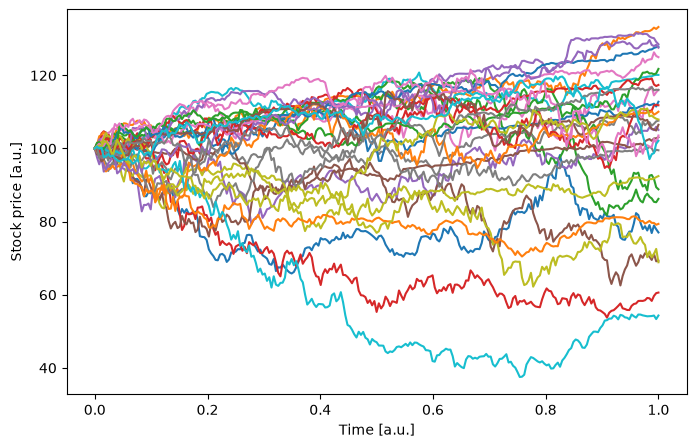

In [7]:
S, v = simulate_heston_paths(S0=S0, v0=v0, rate=rate, dividend_yield=dividend_yield, kappa=kappa, theta=theta,
                              ksi=ksi,rho=rho, T=T, n_steps=n_steps, n_paths=1_000, seed=42)

time = np.linspace(0, T, n_steps + 1)
plt.figure(figsize=(8, 5))
for i in range(30):
    plt.plot(time, S[i])
plt.xlabel("Time [a.u.]")
plt.ylabel("Stock price [a.u.]")
plt.show()

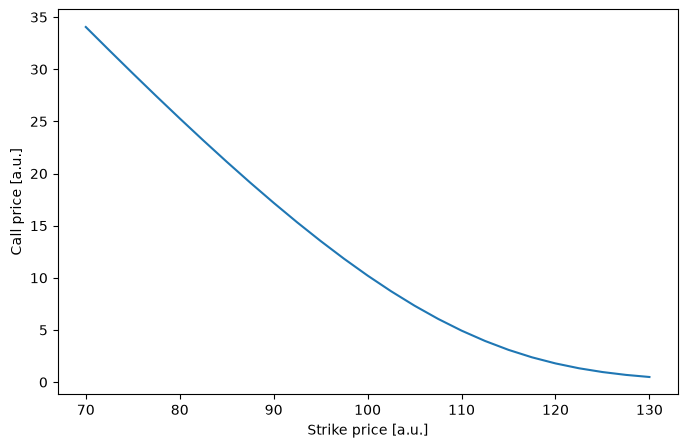

In [8]:
strikes = np.linspace(70, 130, 25)

heston_prices = []
heston_errors = []

for K in strikes:
    price, error = price_heston_call_mc(S0=S0, K=K, v0=v0, rate=rate, dividend_yield=dividend_yield, kappa=kappa,
        theta=theta, ksi=ksi, rho=rho, T=T, n_steps=n_steps, n_paths=n_paths, seed=42)

    heston_prices.append(price)
    heston_errors.append(error)



plt.figure(figsize=(8, 5))

plt.plot(strikes, heston_prices)

plt.xlabel("Strike price [a.u.]")
plt.ylabel("Call price [a.u.]")
plt.show()

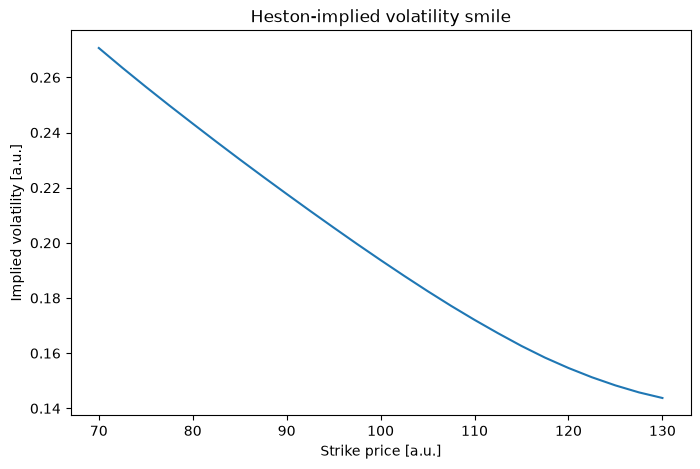

In [ ]:
# Calculate implied volatility from black scholes
implied_vols = []

for K, price in zip(strikes, heston_prices):
    iv = implied_volatility(market_price=price, S0=S0, K=K, rate=rate, T=T, dividend_yield=dividend_yield)
    implied_vols.append(iv)

plt.figure(figsize=(8, 5))
plt.plot(strikes, implied_vols)
plt.xlabel("Strike price [a.u.]")
plt.ylabel("Implied volatility [a.u.]")
plt.title("Heston-implied volatility smile")
plt.show()